In [ ]:
# Inter-channel Phase Difference (IPD)를 정규화하여,
# Direction Strenth를 정의하고, 이를 주파수-시간 영역에서 시각화함으로써
# 협대역 음향 성분의 상대적 방향성을 분석할 수 있는 Direction Strength Spectrum을 제안한다.

Sample Rate : 16000
Shape       : (160000, 2)


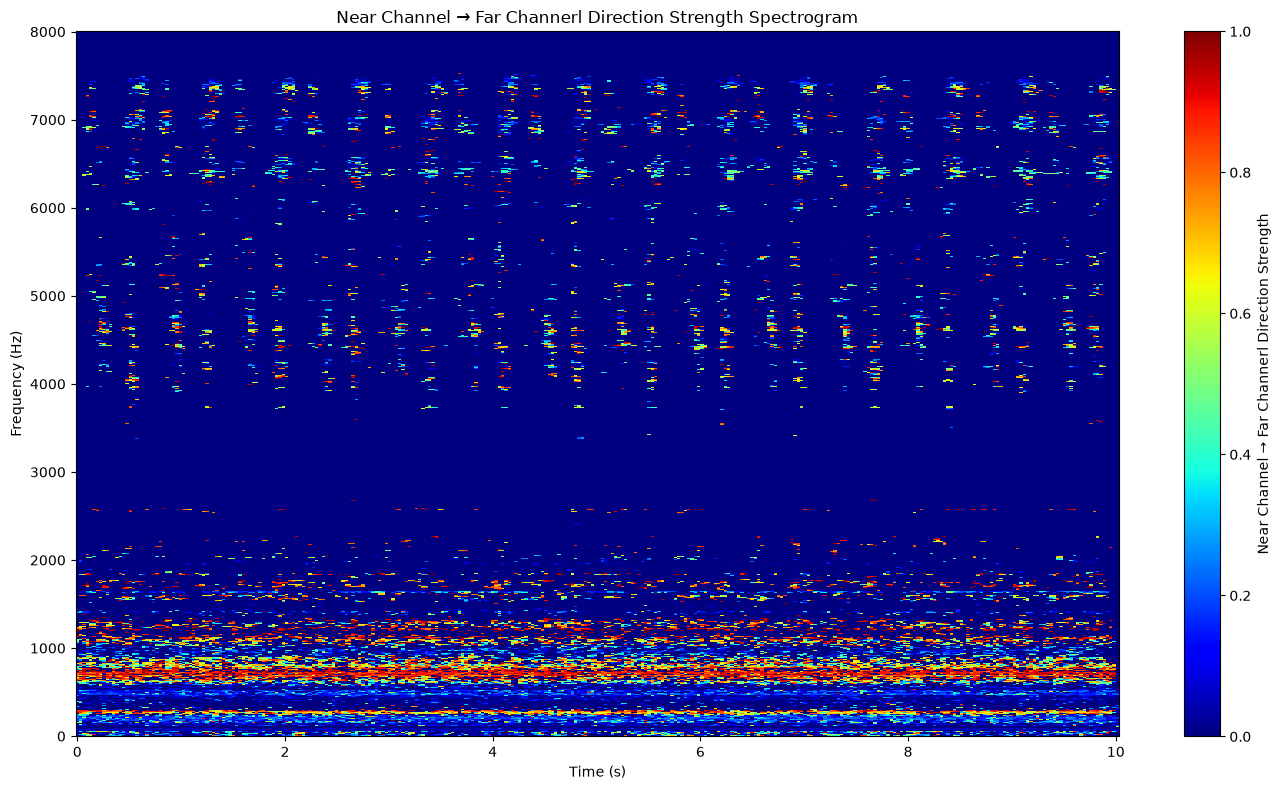


Near Channel → Far Channerl Bin Ratio:  12.12%


In [27]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy. io import wavfile 
from scipy. signal import stft

#============================================
# 설정
#============================================

WAV_FILE = "./fan/test/section_00_source_test_anomaly_0000_spd_1.wav"
NPERSEG = 2048
NOVERLAP = 1536
MAG_PERCENTILE = 80
MAX_FREQ = 8000

#============================================
# WAV 로드
#============================================

fs, data = wavfile.read(WAV_FILE)
print ("Sample Rate :", fs)
print ("Shape       :", data. shape)

if data.ndim != 2:
    raise ValueError(
        " 2채널(Stereo) WAV 파일이 필요합니다."
        )

Near_channel = data[:, 0].astype(np.float64)
Far_channel = data[:, 1].astype(np.float64)

# 정규화
A /= (np.max (np.abs(Far_channel)) + 1e-12)
B /= (np.max (np.abs(Near_channel)) + 1e-12)

#============================================
# STFT
#============================================

freqs, times, ZA = stft(
    A, 
    fs=fs,
    nperseg=NPERSEG, 
    noverlap=NOVERLAP
)

_, _, ZB = stft(
    B, 
    fs=fs,
    nperseg=NPERSEG,
    noverlap=NOVERLAP
)

#============================================
# Cross Spectrum
#============================================

cross = ZA * np.conj (ZB)

# 위상차
phase_diff = np.angle(cross)

# 에너지
magnitude = np.abs(ZA) * np.abs(ZB)

#============================================
# 유효 신호 영역
#============================================

mag_threshold = np.percentile(
    magnitude,
    MAG_PERCENTILE
)

valid_energy = magnitude > mag_threshold

#============================================
# B → A Direction Strength
#============================================

direction_strength = np.zeros_like(
    phase_diff,
    dtype=np.float64
)

mask =(
    (phase_diff < 0) 
    &
    valid_energy
)

direction_strength[mask] = (
    -phase_diff[mask]
) / np.pi

# 0 ~ 1 범위 제한
direction_strength = np.clip(
    direction_strength,
    0,
    1
)

#============================================
# 표시 주파수 제한
#============================================

freq_mask = freqs <= MAX_FREQ
plot_freqs = freqs[freq_mask]
plot_data = direction_strength[freq_mask, :]

#============================================
# Plot
#============================================

plt.figure(figsize=(14, 8))
pcm = plt.pcolormesh(
    times,
    plot_freqs, 
    plot_data, 
    shading="auto",
    cmap='jet',
    vmin=0,
    vmax=1
)

cbar = plt.colorbar(pcm)
cbar. set_label(
    "Near Channel → Far Channerl Direction Strength"
)

plt.xlabel ("Time (s)")
plt.ylabel ("Frequency (Hz)")

plt.title(
"Near Channel → Far Channerl Direction Strength Spectrogram"
)

plt.tight_layout ()
plt.show()

#============================================
# 통계 출력
#============================================

detected_ratio = (
    np.sum (mask) 
    / mask. size
    * 100
)

print()
print(
    f"Near Channel → Far Channerl Bin Ratio: " 
    f"{detected_ratio: .2f}%"
)


Sampling Rate : 16000 Hz
Audio Shape   : (160000, 2)
Duration      : 10.00 sec


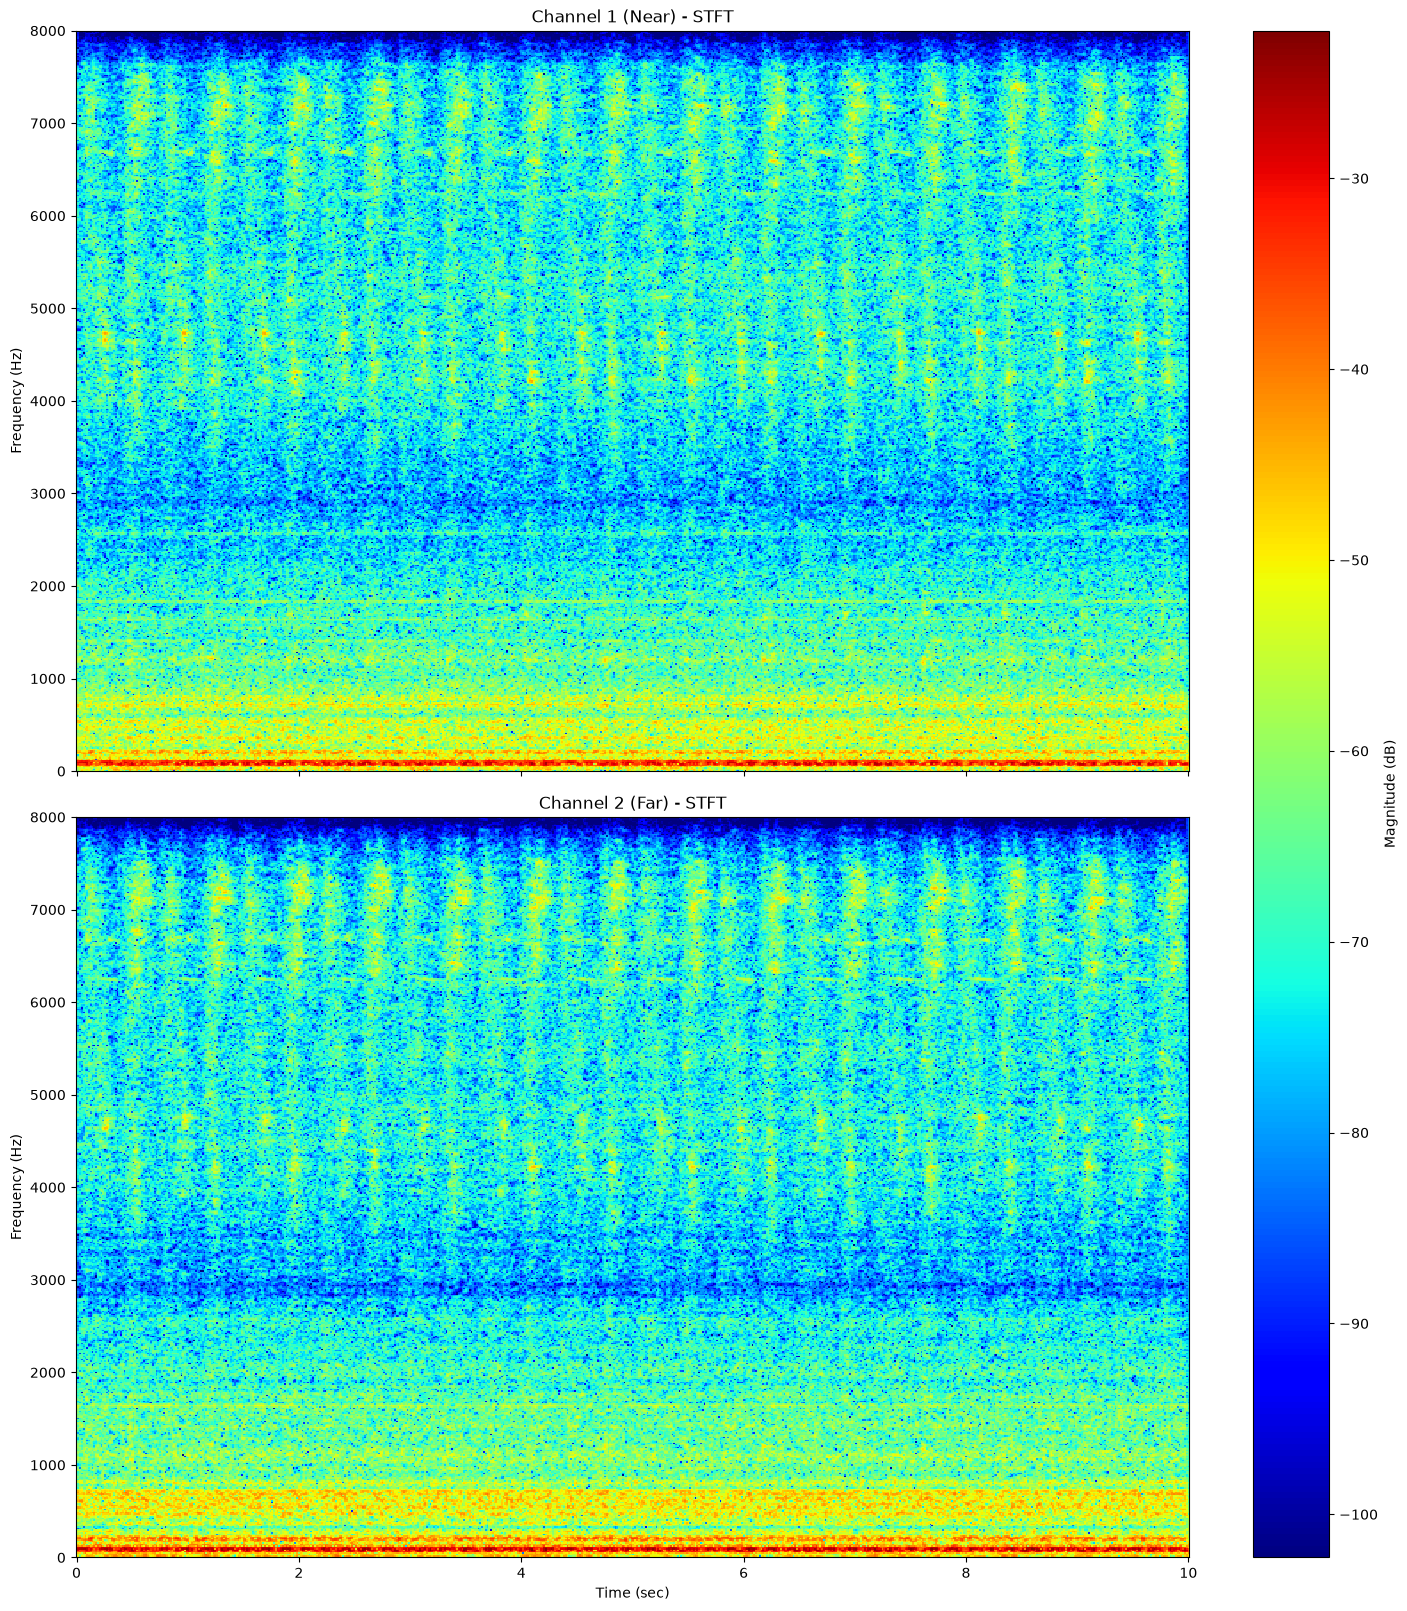

In [26]:

import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

from scipy.signal import stft

# ----------------------------------
# 1. WAV 파일 로딩
# ----------------------------------
wav_path = "./fan/test/section_00_source_test_anomaly_0000_spd_1.wav"

audio, sr = sf.read(wav_path)

print(f"Sampling Rate : {sr} Hz")
print(f"Audio Shape   : {audio.shape}")
print(f"Duration      : {len(audio) / sr:.2f} sec")

# Stereo 확인
if audio.ndim != 2 or audio.shape[1] != 2:
    raise ValueError("Stereo WAV 파일이 필요합니다.")

ch1 = audio[:, 0]
ch2 = audio[:, 1]

# ----------------------------------
# 2. STFT 파라미터
# ----------------------------------
n_fft = 1024
hop_length = 256
noverlap = n_fft - hop_length

# ----------------------------------
# 3. 채널별 STFT
# ----------------------------------
f1, t1, Z1 = stft(
    ch1,
    fs=sr,
    window="hann",
    nperseg=n_fft,
    noverlap=noverlap,
    nfft=n_fft
)

f2, t2, Z2 = stft(
    ch2,
    fs=sr,
    window="hann",
    nperseg=n_fft,
    noverlap=noverlap,
    nfft=n_fft
)

# ----------------------------------
# 4. Magnitude -> dB 변환
# ----------------------------------
eps = 1e-10

S1 = 20 * np.log10(np.maximum(np.abs(Z1), eps))
S2 = 20 * np.log10(np.maximum(np.abs(Z2), eps))

# 동일한 컬러 스케일 적용
vmax = max(S1.max(), S2.max())
vmin = vmax - 80

# ----------------------------------
# 5. Spectrogram 시각화
# ----------------------------------
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 16),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

im1 = axes[0].pcolormesh(
    t1, f1, S1,
    shading="auto",
    cmap="jet",
    vmin=vmin,
    vmax=vmax
)

axes[0].set_title("Channel 1 (Near) - STFT")
axes[0].set_ylabel("Frequency (Hz)")

im2 = axes[1].pcolormesh(
    t2, f2, S2,
    shading="auto",
    cmap="jet",
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title("Channel 2 (Far) - STFT")
axes[1].set_xlabel("Time (sec)")
axes[1].set_ylabel("Frequency (Hz)")

# 분석 주파수 범위
axes[0].set_ylim(0, min(8000, sr / 2))

fig.colorbar(
    im2,
    ax=axes,
    label="Magnitude (dB)"
)

plt.show()
